# Сессионное задание. DiD-оценка умных парковок в шеринге самокатов

Сервис «Вьюн» начисляет бонус за завершение поездки в обозначенной
парковочной зоне. С 15 сентября 2026 года фича включена в четырёх из
двенадцати городов: city_2, city_5, city_7 и city_10. В этом сценарии
пилотные города выбраны заранее. Данные смоделированы.

По `rpu` смотрю, сколько поездок в день приходится на пользователя.
Для guardrail считаю жалобы на завершение поездки и штрафы на 1000 поездок.
Зоны общие для пользователей, поэтому назначение фичи отдельным людям
в одном городе могло бы повлиять и на контрольную группу.

## 0. Данные

Панель «город x день», 12 городов, 90 дней (01.08 - 29.10.2026). В данных заложены:

- разный размер и базовый уровень городов (0.25-0.55 поездок/пользователя в день);
- недельная сезонность (выходные +15-35%);
- дожди как конфаундер (поездок меньше на ~25%; в пилотных городах в post-периоде
  дождей чуть больше - это смещает наивную оценку вниз);
- истинный эффект фичи +8% к `rpu` с дня запуска;
- guardrail: первые 14 дней после запуска +2 жалобы на 1000 поездок (путаница
  с новыми правилами), потом остаточные +0.5.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

plt.rcParams['figure.figsize'] = (11, 4)
rng = np.random.default_rng(20261122)

cities = [f'city_{i}' for i in range(12)]
treated_cities = {'city_2', 'city_5', 'city_7', 'city_10'}
n_days, launch_day = 90, 45
launch_date = pd.Timestamp('2026-08-01') + pd.Timedelta(days=launch_day)

rows = []
for c in cities:
    users = rng.integers(3000, 20000)           # размер города
    base = rng.uniform(0.25, 0.55)              # базовая частота поездок
    wk_uplift = rng.uniform(0.15, 0.35)         # амплитуда выходных
    rain_prob = rng.uniform(0.10, 0.25)
    treated = c in treated_cities
    for d in range(n_days):
        date = pd.Timestamp('2026-08-01') + pd.Timedelta(days=d)
        weekend = int(date.dayofweek >= 5)
        post = int(d >= launch_day)
        # в пилотных городах в post-периоде дождей чуть больше (конфаундер)
        rain = int(rng.random() < rain_prob + (0.05 if (treated and post) else 0.0))
        lam = users * base * (1 + wk_uplift * weekend) * (1 - 0.25 * rain)
        if treated and post:
            lam *= 1.08                          # истинный эффект +8%
        rides = rng.poisson(lam)
        cr = 3.0                                 # жалобы на 1000 поездок
        if treated and post:
            cr += 2.0 if d < launch_day + 14 else 0.5
        complaints = rng.poisson(cr * rides / 1000)
        rows.append([c, date, weekend, rain, post, treated, users, rides, complaints])

df = pd.DataFrame(rows, columns=['city', 'date', 'weekend', 'rain', 'post',
                                 'treated', 'users', 'rides', 'complaints'])
df['rpu'] = df['rides'] / df['users']
df['compl_rate'] = df['complaints'] / df['rides'] * 1000
df['dsl'] = (df['date'] - launch_date).dt.days   # дней от запуска
print(df.shape, '| даты:', df.date.min().date(), '-', df.date.max().date())
df.head()

(1080, 12) | даты: 2026-08-01 - 2026-10-29


,city,date,weekend,rain,post,treated,users,rides,complaints,rpu,compl_rate,dsl
0,city_0,2026-08-01,1,1,0,False,6627,2925,7,0.441376,2.393162,-45
1,city_0,2026-08-02,1,1,0,False,6627,2880,8,0.434586,2.777778,-44
2,city_0,2026-08-03,0,1,0,False,6627,2086,6,0.314773,2.876318,-43
3,city_0,2026-08-04,0,0,0,False,6627,2895,9,0.436849,3.108808,-42
4,city_0,2026-08-05,0,1,0,False,6627,2206,10,0.332881,4.533092,-41


## 1. Разведочный анализ и проверка предпосылок

In [2]:
# Проверка ключа панели и сопоставление размеров на уровне города
assert not df.duplicated(['city', 'date']).any()
assert df.groupby('city').size().eq(n_days).all()
city_size = df[df.post == 0].groupby(['treated', 'city'])['users'].first()
display(city_size.groupby('treated').agg(['size', 'mean', 'median', 'min', 'max']).round(1))

,size,mean,median,min,max
treated,,,,,
False,8,11245.6,9449.5,3070,19364
True,4,16420.5,16811.0,13043,19017


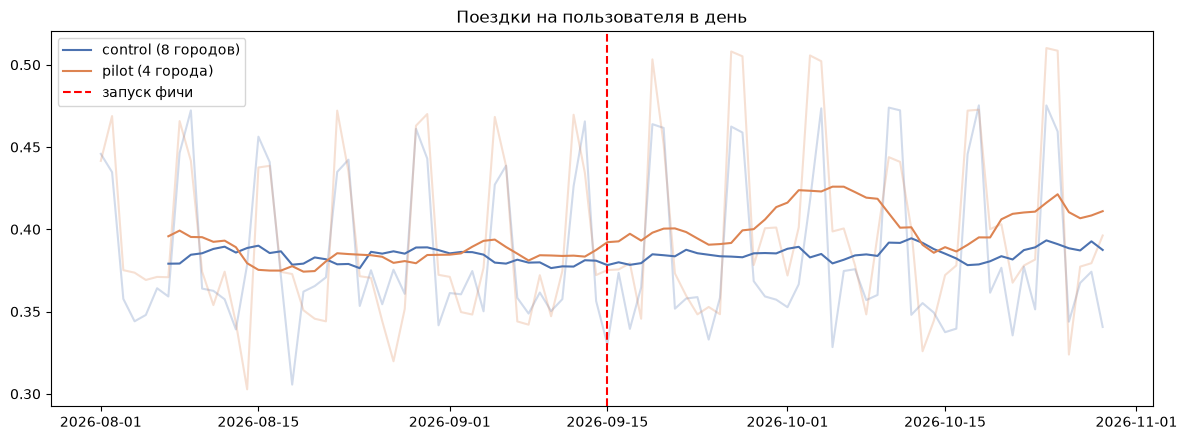

In [3]:
# Тренды rpu по группам городов (7-дневное сглаживание для читаемости)
ts = df.groupby(['date', 'treated'])['rpu'].mean().unstack()
ts_smooth = ts.rolling(7).mean()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(ts.index, ts[False], alpha=0.25, color='#4C72B0')
ax.plot(ts.index, ts[True], alpha=0.25, color='#DD8452')
ax.plot(ts_smooth.index, ts_smooth[False], color='#4C72B0', label='control (8 городов)')
ax.plot(ts_smooth.index, ts_smooth[True], color='#DD8452', label='pilot (4 города)')
ax.axvline(launch_date, color='red', ls='--', label='запуск фичи')
ax.set_title('Поездки на пользователя в день')
ax.legend(); plt.tight_layout(); plt.show()

До запуска ряды визуально близки по динамике, после запуска средний rpu
пилота выше. Скользящее среднее использует последние семь дней.
Недельные отклонения до запуска проверяю отдельно с учётом дождя.

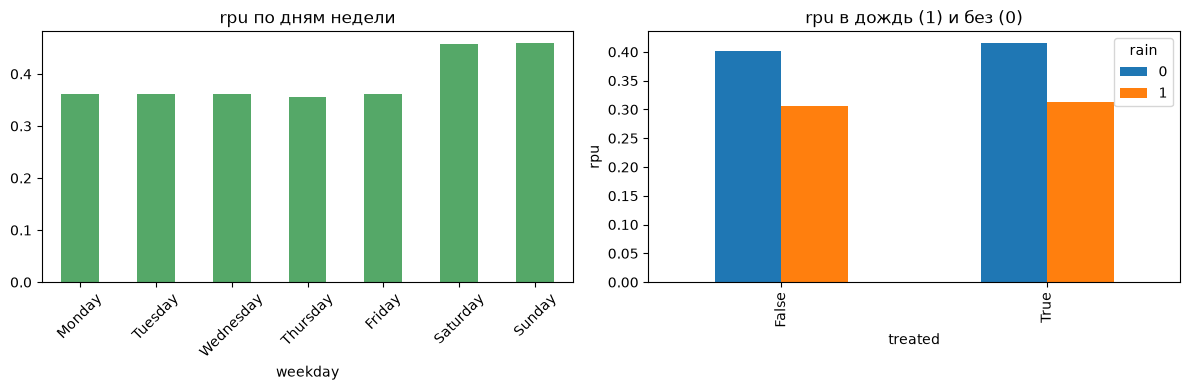

Доля дождливых дней post: pilot 0.233, control 0.172


In [4]:
# Сезонность и дождь - два известных источника колебаний
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df.assign(weekday=df.date.dt.day_name()).groupby('weekday')['rpu'].mean()\
  .reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])\
  .plot.bar(ax=axes[0], color='#55A868')
axes[0].set_title('rpu по дням недели'); axes[0].tick_params(axis='x', rotation=45)

df.groupby(['treated', 'rain'])['rpu'].mean().unstack().plot.bar(ax=axes[1])
axes[1].set_title('rpu в дождь (1) и без (0)'); axes[1].set_ylabel('rpu')
plt.tight_layout(); plt.show()

# Конфаундер: доля дождливых дней в post-периоде
post = df[df.post == 1]
print('Доля дождливых дней post: pilot %.3f, control %.3f'
      % (post[post.treated].rain.mean(), post[~post.treated].rain.mean()))

В выходные поездок на пользователя примерно на четверть больше. После
запуска дождь шёл в 23% городо-дней пилота и 17% городо-дней контроля.
Поскольку в дождь поездок меньше, учитываю погоду в модели.

In [5]:
# Баланс между пилотом и контролем до запуска: уровни и динамика
pre = df[df.post == 0]
city_pre = pre.groupby(['city', 'treated']).agg(
    rpu=('rpu', 'mean')).reset_index()

# баланс уровней по городам (по 12 городам t-тесты грубые, смотрим и на разброс)
print('pre-period rpu: pilot %.4f (sd %.4f), control %.4f (sd %.4f)' % (
    city_pre[city_pre.treated].rpu.mean(), city_pre[city_pre.treated].rpu.std(),
    city_pre[~city_pre.treated].rpu.mean(), city_pre[~city_pre.treated].rpu.std()))
t_stat, p_lvl = stats.ttest_ind(city_pre[city_pre.treated].rpu,
                              city_pre[~city_pre.treated].rpu, equal_var=False)
print('Welch t-test уровней: p = %.3f' % p_lvl)

# амплитуда выходных по группам
for tr in [False, True]:
    s = pre[pre.treated == tr]
    print(f'{"pilot" if tr else "control"}: rpu будни {s[s.weekend==0].rpu.mean():.4f}, '
          f'выходные {s[s.weekend==1].rpu.mean():.4f}')

pre-period rpu: pilot 0.3882 (sd 0.0385), control 0.3850 (sd 0.0935)
Welch t-test уровней: p = 0.936
control: rpu будни 0.3577, выходные 0.4454
pilot: rpu будни 0.3588, выходные 0.4532


Пилотные города крупнее: в среднем 16 421 пользователь на город против 11 246
в контроле. Для сравнения беру размер города один раз, поскольку в симуляции
он постоянен. Средний rpu до запуска близок (0,388 и 0,385, Welch p = 0,936).
Похожий уровень сам по себе ничего не говорит о динамике.

Здесь не было случайной разбивки с заданной пропорцией, поэтому SRM-тест
к пилоту неприменим. Перед оценкой эффекта проверяю динамику групп до запуска.

## 2. Выбор метода

Выбираю DiD с фиксированными эффектами города и дня. Есть общая дата запуска
и города сравнения. Фиксированные эффекты учитывают постоянные различия между городами
и общие календарные колебания. Дождь добавляю как отдельную переменную.

Чтобы интерпретировать результат причинно, предполагаю параллельные тренды
без запуска после учёта погоды, отсутствие эффекта до запуска, перетока
между городами и других событий, одновременно затронувших только пилот.
Порог для RDD и подходящий инструмент для IV отсутствуют. При 12 городах
матчинг по наблюдаемым признакам оставил бы мало пар и зависел бы от их выбора.

Для следующего пилота я бы по возможности рандомизировал города внутри групп
сопоставимого размера и базовой частоты поездок. Для уже проведённого пилота
с заданным списком городов такой дизайн недоступен.

## 3. Проверка предтрендов

Оцениваю динамику в одной регрессии. Коэффициенты показывают, как разрыв
между пилотом и контролем менялся относительно недели перед запуском.
Использую логарифм rpu, эффекты города и дня, поправку на дождь и отдельный
эффект выходных для каждого города относительно базового города.
Стандартные ошибки кластеризованы по городу.

Совместный тест коэффициентов до запуска: p = 0.670


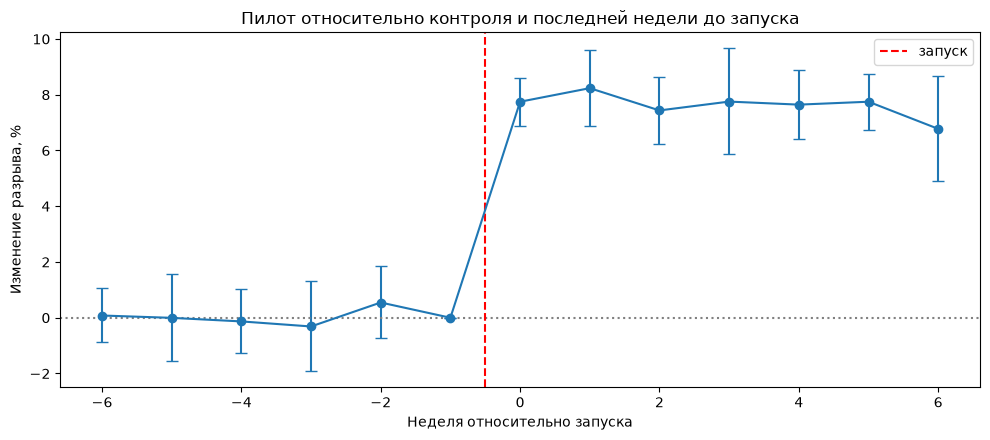

In [6]:
df['day'] = df.date.dt.dayofyear
df['rel_week'] = (df['dsl'] // 7).clip(-6, 6)
event_terms = {}
for week in sorted(df['rel_week'].unique()):
    if week == -1:
        continue  # базовая неделя
    name = f'lead_{-week}' if week < 0 else f'lag_{week}'
    df[name] = (df.treated & df['rel_week'].eq(week)).astype(int)
    event_terms[week] = name

# Общий эффект выходных уже входит в эффекты дня.
city_weekend = []
for city in sorted(df.city.unique())[1:]:
    name = f'weekend_{city}'
    df[name] = ((df.city == city) & df.weekend.eq(1)).astype(int)
    city_weekend.append(name)

rhs = ' + '.join(['rain', 'C(city)', 'C(day)', *city_weekend, *event_terms.values()])
event_model = smf.ols(f'np.log(rpu) ~ {rhs}', data=df).fit(
    cov_type='cluster', cov_kwds={'groups': df.city}, use_t=True)
pretrend = event_model.f_test(', '.join(
    f'{name} = 0' for week, name in event_terms.items() if week < -1))
print(f'Совместный тест коэффициентов до запуска: p = {float(pretrend.pvalue):.3f}')

event_ci = event_model.conf_int()
points = {week: [event_model.params[name], *event_ci.loc[name]]
          for week, name in event_terms.items()}
points[-1] = [0., 0., 0.]
event = pd.DataFrame.from_dict(points, orient='index', columns=['coef', 'lo', 'hi']).sort_index()
event = np.expm1(event) * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.errorbar(event.index, event.coef, yerr=[event.coef - event.lo, event.hi - event.coef],
            fmt='o-', capsize=4)
ax.axhline(0, color='gray', ls=':')
ax.axvline(-0.5, color='red', ls='--', label='запуск')
ax.set(xlabel='Неделя относительно запуска', ylabel='Изменение разрыва, %',
       title='Пилот относительно контроля и последней недели до запуска')
ax.legend()
plt.tight_layout()
plt.show()

До запуска разрыв выглядит стабильным (совместный тест, p = 0,670).
После запуска разрыв растёт.
С четырьмя пилотными городами проверка может пропустить небольшие предтренды,
поэтому параллельные тренды остаются допущением.

## 4. Оценка эффекта

Модель в уровнях даёт изменение поездок на пользователя в день. Логарифм
rpu использую отдельно для оценки относительного изменения. У каждого
города одинаковый вес, поэтому это оценка для среднего города панели.

Результаты ниже используют кластеризацию по городу и t-распределение.
Городов 12, из них четыре пилотных, поэтому ДИ и p-value ориентировочные.

In [7]:
df['tx'] = (df['treated'] & (df['post'] == 1)).astype(int)  # treated x post

def did(data, controls=True, log=False):
    '''DiD-регрессия с кластерными ошибками по городу.'''
    dep = 'np.log(rpu)' if log else 'rpu'
    # weekend не включаем: он - функция дня и уже поглощён эффектами дня
    rhs = 'tx + C(city) + C(day)' + (' + rain' if controls else '')
    m = smf.ols(f'{dep} ~ {rhs}', data=data).fit(
        cov_type='cluster', cov_kwds={'groups': data.city}, use_t=True)
    return m.params['tx'], m.bse['tx'], m.conf_int().loc['tx'].tolist(), m.pvalues['tx']

for label, kw in [('базовая', dict(controls=False, log=False)),
                  ('+ контроли', dict(controls=True, log=False)),
                  ('+ контроли, log', dict(controls=True, log=True))]:
    b, se, ci, p = did(df, **kw)
    print(f'{label:>22}: beta = {b:.4f}  se = {se:.4f}  95% CI [{ci[0]:.4f}, {ci[1]:.4f}]  p = {p:.2g}')
    if kw['log']:
        low, high = np.expm1(ci)
        print(f'Относительное изменение: {np.expm1(b):+.1%}, 95% ДИ [{low:+.1%}, {high:+.1%}]')

               базовая: beta = 0.0173  se = 0.0049  95% CI [0.0065, 0.0281]  p = 0.0049
            + контроли: beta = 0.0286  se = 0.0014  95% CI [0.0255, 0.0318]  p = 5.1e-10
       + контроли, log: beta = 0.0738  se = 0.0022  95% CI [0.0689, 0.0788]  p = 2.5e-12
Относительное изменение: +7.7%, 95% ДИ [+7.1%, +8.2%]


С поправкой на дождь получаю +0,0286 поездки на пользователя в день.
В логарифмической модели прирост составляет +7,7%, близко к заложенным +8%.
Без учёта дождя оценка в уровнях составляет +0,0173.

### 4.1. Чувствительность оценки

Проверяю более короткое окно, исключение крупнейшего города и анализ только
по будням. Отдельно проверяю, изменится ли оценка, если разрешить городам
по-разному реагировать на выходные. Для плацебо сдвигаю старт в период до запуска.

In [8]:
checks = []

# окно +-30 дней вокруг запуска
w30 = df[df.dsl.abs() <= 30]
checks.append(('окно +-30 дней', *did(w30)))

# без крупнейшего города
big = df.groupby('city').users.first().idxmax()
checks.append((f'без {big}', *did(df[df.city != big])))

# только будни (убрать выходную сезонность совсем)
checks.append(('только будни', *did(df[df.weekend == 0])))

# У каждого города может быть своя амплитуда выходных.
mw = smf.ols('rpu ~ tx + rain + C(city) + C(day) + ' + ' + '.join(city_weekend),
             data=df).fit(cov_type='cluster', cov_kwds={'groups': df.city}, use_t=True)
checks.append(('выходные по городам', mw.params['tx'], mw.bse['tx'],
               mw.conf_int().loc['tx'].tolist(), mw.pvalues['tx']))

# плацебо: "запуск" на 25-й день внутри pre-периода
pre = df[df.post == 0].copy()
pre['tx_pl'] = (pre.treated & (pre.dsl >= -25)).astype(int)
mp = smf.ols('rpu ~ tx_pl + rain + C(city) + C(day)', data=pre).fit(
    cov_type='cluster', cov_kwds={'groups': pre.city}, use_t=True)
checks.append(('плацебо-дата', mp.params['tx_pl'], mp.bse['tx_pl'],
               mp.conf_int().loc['tx_pl'].tolist(), mp.pvalues['tx_pl']))

for label, b, se, ci, p in checks:
    print(f'{label:>16}: beta = {b:+.4f}  se = {se:.4f}  95% CI [{ci[0]:+.4f}, {ci[1]:+.4f}]  p = {p:.2g}')

  окно +-30 дней: beta = +0.0287  se = 0.0017  95% CI [+0.0250, +0.0324]  p = 2.9e-09
      без city_9: beta = +0.0285  se = 0.0015  95% CI [+0.0252, +0.0317]  p = 2.7e-09
    только будни: beta = +0.0263  se = 0.0017  95% CI [+0.0224, +0.0301]  p = 1.1e-08
выходные по городам: beta = +0.0286  se = 0.0014  95% CI [+0.0255, +0.0316]  p = 3.5e-10
    плацебо-дата: beta = -0.0006  se = 0.0015  95% CI [-0.0040, +0.0028]  p = 0.71


В моделях с учётом дождя оценки составляют от +0,026 до +0,029 rpu.
Разные эффекты выходных по городам почти не меняют результат. На
плацебо-дате оценка около −0,0006, её интервал включает ноль.

## 5. Guardrail-анализ: жалобы

Использую ту же DiD-модель для частоты жалоб. Дополнительно оцениваю
прирост за первые 14 дней и за остальной период после запуска.

,жалоб на 1000 поездок,"ДИ, нижняя","ДИ, верхняя",p-value
период,,,,
весь период,0.968,0.800,1.136,6.623870e-08
первые 14 дней,1.934,1.646,2.222,2.644747e-08
после 14 дней,0.536,0.334,0.737,1.095828e-04


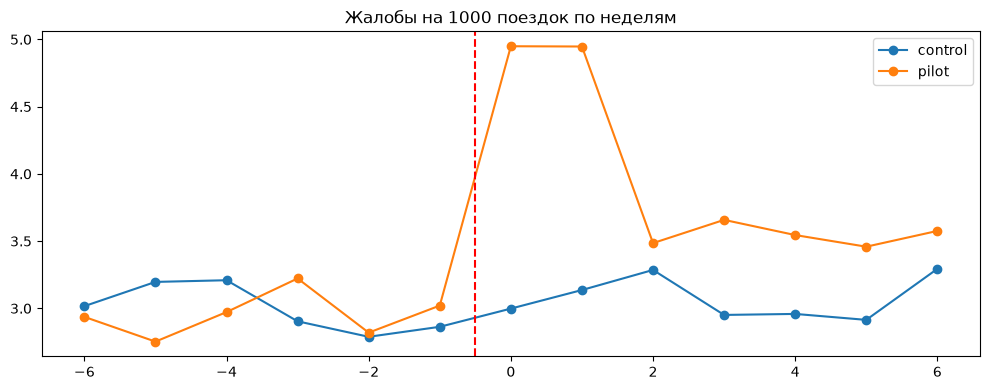

In [9]:
# общий эффект на guardrail
mg = smf.ols('compl_rate ~ tx + rain + C(city) + C(day)', data=df).fit(
    cov_type='cluster', cov_kwds={'groups': df.city}, use_t=True)


# ранняя vs поздняя часть post-периода
df['tx_early'] = ((df.treated) & (df.dsl >= 0) & (df.dsl < 14)).astype(int)
df['tx_late'] = ((df.treated) & (df.dsl >= 14)).astype(int)
ge = smf.ols('compl_rate ~ tx_early + tx_late + rain + C(city) + C(day)',
             data=df).fit(cov_type='cluster', cov_kwds={'groups': df.city}, use_t=True)
from statsmodels.stats.multitest import multipletests

terms = ['tx_early', 'tx_late']
adjusted_p = multipletests(ge.pvalues.loc[terms], method='holm')[1]
rows = [('весь период', mg, 'tx', mg.pvalues['tx']),
        ('первые 14 дней', ge, terms[0], adjusted_p[0]),
        ('после 14 дней', ge, terms[1], adjusted_p[1])]
display(pd.DataFrame([
    {'период': label, 'жалоб на 1000 поездок': model.params[term],
     'ДИ, нижняя': model.conf_int().loc[term, 0], 'ДИ, верхняя': model.conf_int().loc[term, 1],
     'p-value': p}
    for label, model, term, p in rows
]).set_index('период').round({'жалоб на 1000 поездок': 3, 'ДИ, нижняя': 3, 'ДИ, верхняя': 3}))

# динамика жалоб по неделям
df['rel_week'] = (df['dsl'] // 7).clip(-6, 6)
gw = df.groupby(['rel_week', 'treated'])['compl_rate'].mean().unstack()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(gw.index, gw[False], 'o-', label='control')
ax.plot(gw.index, gw[True], 'o-', label='pilot')
ax.axvline(-0.5, color='red', ls='--')
ax.set_title('Жалобы на 1000 поездок по неделям'); ax.legend()
plt.tight_layout(); plt.show()

После запуска в среднем добавилось 0,97 жалобы на 1000 поездок. В первые
две недели прирост составил 1,93, затем снизился до 0,54. В таблице p-value
для двух периодов скорректированы по Холму, интервалы показаны для каждой
оценки отдельно. Подсказки при завершении поездки стоит проверить следующим
пилотом: по этим данным видна динамика жалоб, а их конкретная причина неизвестна.

## 6. Сравнение с наивной оценкой

In [10]:
post = df[df.post == 1]
naive = post[post.treated].rpu.mean() - post[~post.treated].rpu.mean()
did_no_rain, *_ = did(df, controls=False)
did_rain, *_ = did(df)
display(pd.Series({
    'Разница средних после запуска': naive,
    'DiD без дождя': did_no_rain,
    'DiD с дождём': did_rain,
}, name='Поездки на пользователя в день').round(4).to_frame())
display(df.groupby(['treated', 'post'])['rain'].mean().unstack().round(3))

,Поездки на пользователя в день
Разница средних после запуска,0.0205
DiD без дождя,0.0173
DiD с дождём,0.0286


post,0,1
treated,,
False,0.183,0.172
True,0.133,0.233


Разница средних после запуска составила +0,0205 rpu. В DiD поправка на дождь поднимает оценку с +0,0173 до +0,0286. В пилоте доля дождливых дней
выросла с 13,3% до 23,3%, а в контроле снизилась с 18,3% до 17,2%.

## 7. Продуктовый вывод

**Доработать фичу и повторить пилот.** В симуляции частота поездок выросла
примерно на 7,7%, но даже после первых двух недель остаётся около
0,54 дополнительной жалобы на 1000 поездок.

В следующем пилоте я бы добавил подсказку при первом завершении поездки в
новой зоне и проверил сценарий предупреждения вместо первого штрафа.
Перед расширением заранее согласовал бы допустимый прирост жалоб и проверил,
что дополнительная маржа от поездок покрывает бонусы и расходы на поддержку.
В данных нет затрат и выручки, поэтому экономику запуска здесь оценить нельзя.